In [1]:
import os

for root, dirs, files in os.walk('/kaggle/input'):
    print(root)

/kaggle/input
/kaggle/input/datasets
/kaggle/input/datasets/jshanky
/kaggle/input/datasets/jshanky/zenodo
/kaggle/input/datasets/jshanky/zenodo/Zenodo
/kaggle/input/datasets/jshanky/zenodo/Zenodo/updated train dataset
/kaggle/input/datasets/jshanky/zenodo/Zenodo/updated train dataset/images
/kaggle/input/datasets/jshanky/zenodo/Zenodo/updated test dataset
/kaggle/input/datasets/jshanky/zenodo/Zenodo/updated test dataset/images


In [2]:
import os
import shutil
import pandas as pd

# Original dataset paths
train_source = '/kaggle/input/datasets/jshanky/zenodo/Zenodo/updated train dataset'
test_source = '/kaggle/input/datasets/jshanky/zenodo/Zenodo/updated test dataset'

# Label files
train_excel = os.path.join(train_source, 'class_label.xlsx')
test_csv = os.path.join(test_source, 'class label.csv')

# Image folders
train_images = os.path.join(train_source, 'images')
test_images = os.path.join(test_source, 'images')

# New folders for ImageFolder
output_root = '/kaggle/working/PCOSGen-train'

train_dir = os.path.join(output_root, 'train')
test_dir = os.path.join(output_root, 'test')

# Create class folders
for directory in [
    os.path.join(train_dir, 'Appears normal'),
    os.path.join(train_dir, 'Appears abnormal'),
    os.path.join(test_dir, 'Appears normal'),
    os.path.join(test_dir, 'Appears abnormal')
]:
    os.makedirs(directory, exist_ok=True)

# Read labels
train_df = pd.read_excel(train_excel)
test_df = pd.read_csv(test_csv)

# Column we actually want
label_column = 'Class label (whether the ultrasound images appears normal or has some abnormality)'

# Function to copy images according to labels
def prepare_dataset(df, image_source, output_dir):
    copied = 0
    skipped = 0

    for _, row in df.iterrows():

        image_path = str(row['imagePath']).strip()
        label = str(row[label_column]).strip().lower()

        # Ignore Unknown / missing labels
        if label == 'unknown' or label == 'nan':
            skipped += 1
            continue

        # Determine target class
        if 'normal' in label and 'abnormal' not in label:
            class_name = 'Appears normal'
        elif 'abnormal' in label:
            class_name = 'Appears abnormal'
        else:
            skipped += 1
            continue

        # ImagePath may contain directories, so use only the filename
        image_name = os.path.basename(image_path)
        source_file = os.path.join(image_source, image_name)

        if not os.path.exists(source_file):
            skipped += 1
            continue

        destination = os.path.join(output_dir, class_name, image_name)

        shutil.copy2(source_file, destination)
        copied += 1

    return copied, skipped


# Prepare train and test
train_copied, train_skipped = prepare_dataset(
    train_df,
    train_images,
    train_dir
)

test_copied, test_skipped = prepare_dataset(
    test_df,
    test_images,
    test_dir
)

print("Dataset preparation complete!")
print(f"Train images copied : {train_copied}")
print(f"Train images skipped: {train_skipped}")
print(f"Test images copied  : {test_copied}")
print(f"Test images skipped : {test_skipped}")

Dataset preparation complete!
Train images copied : 3200
Train images skipped: 1
Test images copied  : 1468
Test images skipped : 0


In [3]:
from collections import Counter
import os

for split in ['train', 'test']:
    print(f"\n{split.upper()}")

    for class_name in ['Appears normal', 'Appears abnormal']:
        path = os.path.join(output_root, split, class_name)
        count = len(os.listdir(path))
        print(f"{class_name}: {count}")


TRAIN
Appears normal: 903
Appears abnormal: 2297

TEST
Appears normal: 416
Appears abnormal: 1052


Device: cuda


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=EfficientNet_B3_Weights.IMAGENET1K_V1`. You can also use `weights=EfficientNet_B3_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/efficientnet_b3_rwightman-b3899882.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b3_rwightman-b3899882.pth


100%|██████████| 47.2M/47.2M [00:00<00:00, 182MB/s] 



Classes: ['Appears abnormal', 'Appears normal']
Number of classes: 2


...


Epoch [9/50] Train Loss: 0.3934 (CE: 0.4781, Dice: 0.3087), Train Acc: 0.7404 | Val Loss: 0.5826 (CE: 0.7844, Dice: 0.3807), Val Acc: 0.6000
  -> No improvement for 7/8 epochs


Epoch 10/50: 100%|██████████| 85/85 [01:04<00:00,  1.31it/s]



Epoch [10/50] Train Loss: 0.4063 (CE: 0.4912, Dice: 0.3213), Train Acc: 0.7261 | Val Loss: 0.4572 (CE: 0.5574, Dice: 0.3569), Val Acc: 0.6729
  -> No improvement for 8/8 epochs

Early stopping triggered at epoch 10. Best Val Accuracy: 0.7562


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)



Final EfficientNet-B3 Test Loss: 0.6444 (CE: 0.7620, Dice: 0.5267), Final EfficientNet-B3 Test Accuracy: 0.9067

EfficientNet-B3 Test Precision (weighted): 0.9115
EfficientNet-B3 Test Recall (weighted): 0.9067
EfficientNet-B3 Test F1-score (weighted): 0.9018

EfficientNet-B3 Per-class report:
                  precision    recall  f1-score   support

Appears abnormal     0.8934    0.9876    0.9381      1052
  Appears normal     0.9574    0.7019    0.8100       416

        accuracy                         0.9067      1468
       macro avg     0.9254    0.8448    0.8741      1468
    weighted avg     0.9115    0.9067    0.9018      1468



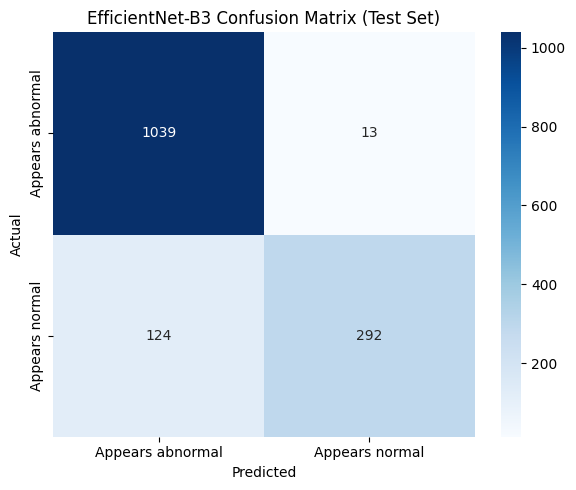

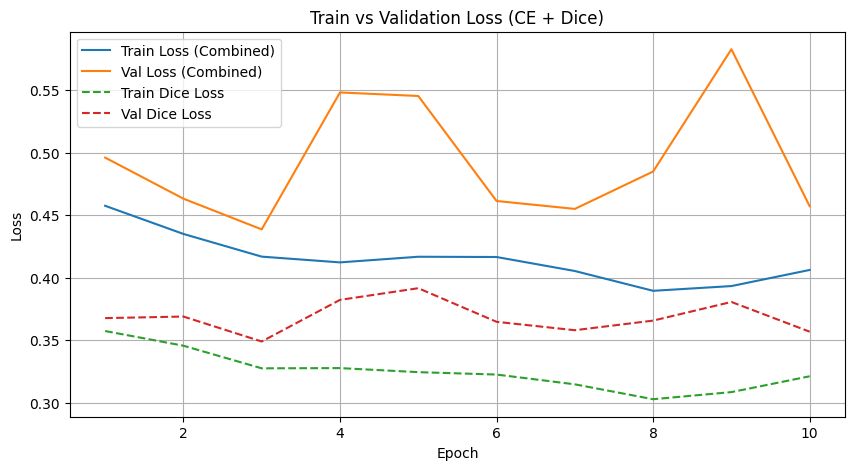

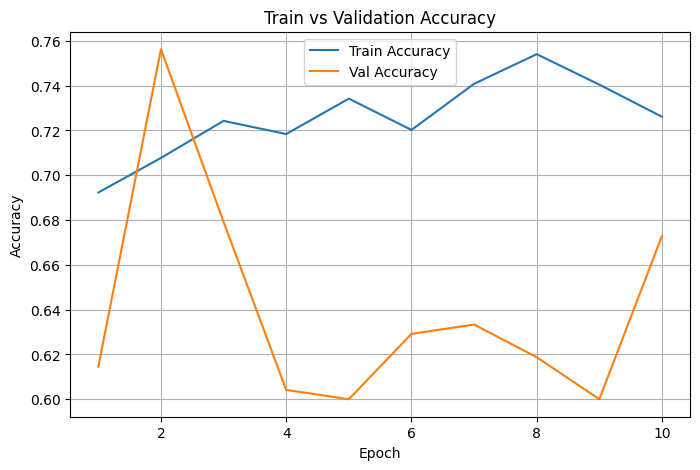


================ FINAL SUMMARY ================
Best EfficientNet-B3 Val Accuracy: 0.7562
EfficientNet-B3 Test Accuracy: 0.9067
EfficientNet-B3 Test Precision: 0.9115
EfficientNet-B3 Test Recall: 0.9067
EfficientNet-B3 Test F1-score: 0.9018
EfficientNet-B3 Test Dice Loss: 0.5267


In [6]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, WeightedRandomSampler, random_split
from torchvision import datasets, transforms, models
from tqdm import tqdm
import numpy as np
import os
import matplotlib.pyplot as plt

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

import seaborn as sns


# ============================================================
# Device configuration
# ============================================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)


# ============================================================
# Paths
# ============================================================

train_dir = '/kaggle/working/PCOSGen-train/train'
test_dir = '/kaggle/working/PCOSGen-train/test'


# ============================================================
# Image transformations
# EfficientNet-B3 -> 300 x 300
# ============================================================

train_transform = transforms.Compose([
    transforms.Resize((300, 300)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(20),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


test_transform = transforms.Compose([
    transforms.Resize((300, 300)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


# ============================================================
# Datasets
# ============================================================

train_dataset = datasets.ImageFolder(
    train_dir,
    transform=train_transform
)

test_dataset = datasets.ImageFolder(
    test_dir,
    transform=test_transform
)


# ============================================================
# 85/15 Train-Validation Split
# ============================================================

val_size = int(
    0.15 * len(train_dataset)
)

train_size = (
    len(train_dataset) - val_size
)

train_subset, val_subset = random_split(
    train_dataset,
    [train_size, val_size]
)


# ============================================================
# Class weights for WeightedRandomSampler
# ============================================================

train_targets = [
    train_dataset.targets[i]
    for i in train_subset.indices
]

class_counts = np.bincount(
    train_targets
)

class_weights = 1.0 / class_counts

sample_weights = [
    class_weights[label]
    for label in train_targets
]


# ============================================================
# Weighted Random Sampler
# ============================================================

sampler = WeightedRandomSampler(
    weights=sample_weights,
    num_samples=len(train_subset),
    replacement=True
)


# ============================================================
# DataLoaders
# ============================================================

train_loader = DataLoader(
    train_subset,
    batch_size=32,
    sampler=sampler
)

val_loader = DataLoader(
    val_subset,
    batch_size=32,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False
)


# ============================================================
# Load EfficientNet-B3
# ============================================================

efficientnet = models.efficientnet_b3(
    pretrained=True
)

num_classes = len(
    train_dataset.classes
)


# ============================================================
# Replace EfficientNet-B3 classifier
# ============================================================

efficientnet.classifier[1] = nn.Linear(
    efficientnet.classifier[1].in_features,
    num_classes
)

efficientnet = efficientnet.to(device)


print("\nClasses:", train_dataset.classes)

print(
    "Number of classes:",
    num_classes
)


# ============================================================
# Dice Loss
# ============================================================

class DiceLoss(nn.Module):

    def __init__(
        self,
        num_classes,
        smooth=1e-6
    ):

        super().__init__()

        self.num_classes = num_classes
        self.smooth = smooth


    def forward(
        self,
        logits,
        targets
    ):

        probs = F.softmax(
            logits,
            dim=1
        )

        targets_one_hot = F.one_hot(
            targets,
            num_classes=self.num_classes
        ).float()

        intersection = (
            probs * targets_one_hot
        ).sum(dim=0)

        union = (
            probs.sum(dim=0)
            +
            targets_one_hot.sum(dim=0)
        )

        dice_score = (
            2.0 * intersection
            +
            self.smooth
        ) / (
            union
            +
            self.smooth
        )

        dice_loss = (
            1.0 -
            dice_score.mean()
        )

        return dice_loss


# ============================================================
# Combined CrossEntropy + Dice Loss
# ============================================================

class CombinedLoss(nn.Module):

    def __init__(
        self,
        num_classes,
        ce_weight=0.5,
        dice_weight=0.5
    ):

        super().__init__()

        self.ce_loss = nn.CrossEntropyLoss()

        self.dice_loss = DiceLoss(
            num_classes
        )

        self.ce_weight = ce_weight
        self.dice_weight = dice_weight


    def forward(
        self,
        logits,
        targets
    ):

        ce = self.ce_loss(
            logits,
            targets
        )

        dice = self.dice_loss(
            logits,
            targets
        )

        total = (
            self.ce_weight * ce
            +
            self.dice_weight * dice
        )

        return total, ce, dice


criterion = CombinedLoss(
    num_classes=num_classes,
    ce_weight=0.5,
    dice_weight=0.5
)


# ============================================================
# Optimizer
# ============================================================

optimizer = optim.Adam(
    efficientnet.parameters(),
    lr=0.001
)


# ============================================================
# Evaluation Function
# ============================================================

def evaluate_model(
    model,
    loader
):

    model.eval()

    correct = 0
    total = 0

    running_loss = 0.0
    running_ce = 0.0
    running_dice = 0.0

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss, ce, dice = criterion(
                outputs,
                labels
            )

            running_loss += loss.item()
            running_ce += ce.item()
            running_dice += dice.item()

            _, predicted = torch.max(
                outputs,
                1
            )

            total += labels.size(0)

            correct += (
                predicted == labels
            ).sum().item()


    accuracy = correct / total

    n = len(loader)

    return (
        accuracy,
        running_loss / n,
        running_ce / n,
        running_dice / n
    )


# ============================================================
# Get Predictions
# ============================================================

def get_predictions(
    model,
    loader
):

    model.eval()

    all_preds = []
    all_labels = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            _, predicted = torch.max(
                outputs,
                1
            )

            all_preds.extend(
                predicted.cpu().numpy()
            )

            all_labels.extend(
                labels.cpu().numpy()
            )

    return all_labels, all_preds


# ============================================================
# Early Stopping
# ============================================================

best_accuracy = 0.0

best_model_path = (
    "EfficientNetB3_Baseline.pkl"
)

patience = 8

epochs_no_improve = 0

max_epochs = 50


# ============================================================
# Lists for Graphs
# ============================================================

train_losses = []
train_accs = []

val_losses = []
val_accs = []

train_ce_losses = []
train_dice_losses = []

val_ce_losses = []
val_dice_losses = []


# ============================================================
# Train EfficientNet-B3
# ============================================================

for epoch in range(max_epochs):

    efficientnet.train()

    running_loss = 0.0
    running_ce = 0.0
    running_dice = 0.0

    correct_train = 0
    total_train = 0


    for images, labels in tqdm(
        train_loader,
        desc=f"Epoch {epoch + 1}/{max_epochs}"
    ):

        images = images.to(device)
        labels = labels.to(device)

        outputs = efficientnet(
            images
        )

        loss, ce, dice = criterion(
            outputs,
            labels
        )

        optimizer.zero_grad()

        loss.backward()

        optimizer.step()


        running_loss += loss.item()
        running_ce += ce.item()
        running_dice += dice.item()


        _, predicted = torch.max(
            outputs,
            1
        )

        total_train += labels.size(0)

        correct_train += (
            predicted == labels
        ).sum().item()


    # ========================================================
    # Training metrics
    # ========================================================

    train_accuracy = (
        correct_train /
        total_train
    )

    n_batches = len(
        train_loader
    )

    train_loss = (
        running_loss /
        n_batches
    )

    train_ce = (
        running_ce /
        n_batches
    )

    train_dice = (
        running_dice /
        n_batches
    )


    # ========================================================
    # Validation
    # ========================================================

    val_accuracy, val_loss, val_ce, val_dice = evaluate_model(
        efficientnet,
        val_loader
    )


    # ========================================================
    # Save metrics for graphs
    # ========================================================

    train_losses.append(
        train_loss
    )

    train_accs.append(
        train_accuracy
    )

    val_losses.append(
        val_loss
    )

    val_accs.append(
        val_accuracy
    )

    train_ce_losses.append(
        train_ce
    )

    train_dice_losses.append(
        train_dice
    )

    val_ce_losses.append(
        val_ce
    )

    val_dice_losses.append(
        val_dice
    )


    # ========================================================
    # Print results
    # ========================================================

    print(
        f"\nEpoch [{epoch + 1}/{max_epochs}] "
        f"Train Loss: {train_loss:.4f} "
        f"(CE: {train_ce:.4f}, "
        f"Dice: {train_dice:.4f}), "
        f"Train Acc: {train_accuracy:.4f} | "
        f"Val Loss: {val_loss:.4f} "
        f"(CE: {val_ce:.4f}, "
        f"Dice: {val_dice:.4f}), "
        f"Val Acc: {val_accuracy:.4f}"
    )


    # ========================================================
    # Early Stopping
    # ========================================================

    if val_accuracy > best_accuracy:

        best_accuracy = val_accuracy

        epochs_no_improve = 0

        print(
            f"  -> Saving best model "
            f"(Val Accuracy: "
            f"{best_accuracy:.4f})"
        )

        torch.save(
            efficientnet.state_dict(),
            best_model_path
        )

    else:

        epochs_no_improve += 1

        print(
            f"  -> No improvement for "
            f"{epochs_no_improve}/{patience} epochs"
        )


    if epochs_no_improve >= patience:

        print(
            f"\nEarly stopping triggered at "
            f"epoch {epoch + 1}. "
            f"Best Val Accuracy: "
            f"{best_accuracy:.4f}"
        )

        break


# ============================================================
# Load Best EfficientNet-B3
# ============================================================

best_efficientnet_model = models.efficientnet_b3(
    pretrained=False
)

best_efficientnet_model.classifier[1] = nn.Linear(
    efficientnet.classifier[1].in_features,
    num_classes
)

best_efficientnet_model = (
    best_efficientnet_model.to(device)
)

best_efficientnet_model.load_state_dict(
    torch.load(
        best_model_path
    )
)


# ============================================================
# FINAL TEST EVALUATION
# ============================================================

test_accuracy, test_loss, test_ce, test_dice = evaluate_model(
    best_efficientnet_model,
    test_loader
)


print(
    f"\nFinal EfficientNet-B3 Test Loss: "
    f"{test_loss:.4f} "
    f"(CE: {test_ce:.4f}, "
    f"Dice: {test_dice:.4f}), "
    f"Final EfficientNet-B3 Test Accuracy: "
    f"{test_accuracy:.4f}"
)


# ============================================================
# TEST METRICS
# ============================================================

true_labels, pred_labels = get_predictions(
    best_efficientnet_model,
    test_loader
)

class_names = train_dataset.classes


# Weighted Precision
precision = precision_score(
    true_labels,
    pred_labels,
    average='weighted',
    zero_division=0
)


# Weighted Recall
recall = recall_score(
    true_labels,
    pred_labels,
    average='weighted',
    zero_division=0
)


# Weighted F1
f1 = f1_score(
    true_labels,
    pred_labels,
    average='weighted',
    zero_division=0
)


print(
    f"\nEfficientNet-B3 Test Precision "
    f"(weighted): {precision:.4f}"
)

print(
    f"EfficientNet-B3 Test Recall "
    f"(weighted): {recall:.4f}"
)

print(
    f"EfficientNet-B3 Test F1-score "
    f"(weighted): {f1:.4f}"
)


# ============================================================
# Classification Report
# ============================================================

print(
    "\nEfficientNet-B3 Per-class report:"
)

print(
    classification_report(
        true_labels,
        pred_labels,
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)


# ============================================================
# Confusion Matrix
# ============================================================

cm = confusion_matrix(
    true_labels,
    pred_labels
)

plt.figure(
    figsize=(6, 5)
)

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel(
    'Predicted'
)

plt.ylabel(
    'Actual'
)

plt.title(
    'EfficientNet-B3 Confusion Matrix (Test Set)'
)

plt.tight_layout()

plt.show()


# ============================================================
# Plot Train vs Validation Loss
# ============================================================

epochs_range = range(
    1,
    len(train_losses) + 1
)

plt.figure(
    figsize=(10, 5)
)

plt.plot(
    epochs_range,
    train_losses,
    label='Train Loss (Combined)'
)

plt.plot(
    epochs_range,
    val_losses,
    label='Val Loss (Combined)'
)

plt.plot(
    epochs_range,
    train_dice_losses,
    '--',
    label='Train Dice Loss'
)

plt.plot(
    epochs_range,
    val_dice_losses,
    '--',
    label='Val Dice Loss'
)

plt.xlabel(
    'Epoch'
)

plt.ylabel(
    'Loss'
)

plt.title(
    'Train vs Validation Loss (CE + Dice)'
)

plt.legend()

plt.grid(True)

plt.show()


# ============================================================
# Plot Train vs Validation Accuracy
# ============================================================

plt.figure(
    figsize=(8, 5)
)

plt.plot(
    epochs_range,
    train_accs,
    label='Train Accuracy'
)

plt.plot(
    epochs_range,
    val_accs,
    label='Val Accuracy'
)

plt.xlabel(
    'Epoch'
)

plt.ylabel(
    'Accuracy'
)

plt.title(
    'Train vs Validation Accuracy'
)

plt.legend()

plt.grid(True)

plt.show()


# ============================================================
# FINAL SUMMARY
# ============================================================

print(
    "\n================ FINAL SUMMARY ================"
)

print(
    f"Best EfficientNet-B3 Val Accuracy: "
    f"{best_accuracy:.4f}"
)

print(
    f"EfficientNet-B3 Test Accuracy: "
    f"{test_accuracy:.4f}"
)

print(
    f"EfficientNet-B3 Test Precision: "
    f"{precision:.4f}"
)

print(
    f"EfficientNet-B3 Test Recall: "
    f"{recall:.4f}"
)

print(
    f"EfficientNet-B3 Test F1-score: "
    f"{f1:.4f}"
)

print(
    f"EfficientNet-B3 Test Dice Loss: "
    f"{test_dice:.4f}"
)

# Random Forest


Extracting EfficientNet-B3 features...


Extracting EfficientNet-B3 Features: 100%|██████████| 46/46 [00:10<00:00,  4.54it/s]



Feature shapes:
Train: (2720, 1536)
Validation: (480, 1536)
Test: (1468, 1536)

================ Random Forest ================

Training Random Forest...

Random Forest Validation Accuracy: 0.6833
Random Forest Test Accuracy: 0.9237
Random Forest Test Precision: 0.9240
Random Forest Test Recall: 0.9237
Random Forest Test F1-score: 0.9217

Random Forest Per-class report:
                  precision    recall  f1-score   support

Appears abnormal     0.9219    0.9762    0.9483      1052
  Appears normal     0.9294    0.7909    0.8545       416

        accuracy                         0.9237      1468
       macro avg     0.9256    0.8836    0.9014      1468
    weighted avg     0.9240    0.9237    0.9217      1468



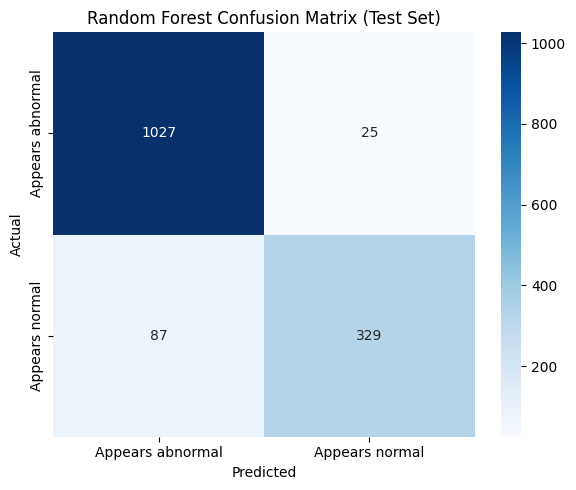


================ RANDOM FOREST SUMMARY ================
Random Forest Validation Accuracy: 0.6833
Random Forest Test Accuracy: 0.9237
Random Forest Test Precision: 0.9240
Random Forest Test Recall: 0.9237
Random Forest Test F1-score: 0.9217


In [7]:
# ============================================================
# EFFICIENTNET-B3 + RANDOM FOREST
# Run this in the NEXT CELL after the baseline
# ============================================================

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)


# ============================================================
# Feature Extraction Function
# ============================================================

def extract_features(model, loader):

    model.eval()

    features = []
    labels_list = []

    with torch.no_grad():

        for images, labels in tqdm(
            loader,
            desc="Extracting EfficientNet-B3 Features"
        ):

            images = images.to(device)

            # Extract features before EfficientNet classifier
            x = model.features(images)

            # Global Average Pooling
            x = F.adaptive_avg_pool2d(
                x,
                (1, 1)
            )

            # Flatten
            x = torch.flatten(
                x,
                1
            )

            features.extend(
                x.cpu().numpy()
            )

            labels_list.extend(
                labels.numpy()
            )

    return (
        np.array(features),
        np.array(labels_list)
    )


# ============================================================
# Extract Train / Validation / Test Features
# ============================================================

print(
    "\nExtracting EfficientNet-B3 features..."
)

train_features, train_labels = extract_features(
    best_efficientnet_model,
    train_loader
)

val_features, val_labels = extract_features(
    best_efficientnet_model,
    val_loader
)

test_features, test_labels = extract_features(
    best_efficientnet_model,
    test_loader
)


print(
    "\nFeature shapes:"
)

print(
    "Train:",
    train_features.shape
)

print(
    "Validation:",
    val_features.shape
)

print(
    "Test:",
    test_features.shape
)


# ============================================================
# Random Forest Classifier
# ============================================================

print(
    "\n================ Random Forest ================"
)

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight='balanced'
)


# ============================================================
# Train Random Forest
# ============================================================

print(
    "\nTraining Random Forest..."
)

rf_model.fit(
    train_features,
    train_labels
)


# ============================================================
# Validation Prediction
# ============================================================

rf_val_preds = rf_model.predict(
    val_features
)

rf_val_accuracy = np.mean(
    rf_val_preds == val_labels
)

print(
    f"\nRandom Forest Validation Accuracy: "
    f"{rf_val_accuracy:.4f}"
)


# ============================================================
# Test Prediction
# ============================================================

rf_test_preds = rf_model.predict(
    test_features
)

rf_test_accuracy = np.mean(
    rf_test_preds == test_labels
)

print(
    f"Random Forest Test Accuracy: "
    f"{rf_test_accuracy:.4f}"
)


# ============================================================
# Test Metrics
# ============================================================

class_names = train_dataset.classes


rf_precision = precision_score(
    test_labels,
    rf_test_preds,
    average='weighted',
    zero_division=0
)

rf_recall = recall_score(
    test_labels,
    rf_test_preds,
    average='weighted',
    zero_division=0
)

rf_f1 = f1_score(
    test_labels,
    rf_test_preds,
    average='weighted',
    zero_division=0
)


print(
    f"Random Forest Test Precision: "
    f"{rf_precision:.4f}"
)

print(
    f"Random Forest Test Recall: "
    f"{rf_recall:.4f}"
)

print(
    f"Random Forest Test F1-score: "
    f"{rf_f1:.4f}"
)


# ============================================================
# Classification Report
# ============================================================

print(
    "\nRandom Forest Per-class report:"
)

print(
    classification_report(
        test_labels,
        rf_test_preds,
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)


# ============================================================
# Confusion Matrix
# ============================================================

rf_cm = confusion_matrix(
    test_labels,
    rf_test_preds
)

plt.figure(
    figsize=(6, 5)
)

sns.heatmap(
    rf_cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel(
    'Predicted'
)

plt.ylabel(
    'Actual'
)

plt.title(
    'Random Forest Confusion Matrix (Test Set)'
)

plt.tight_layout()

plt.show()


# ============================================================
# Random Forest Summary
# ============================================================

print(
    "\n================ RANDOM FOREST SUMMARY ================"
)

print(
    f"Random Forest Validation Accuracy: "
    f"{rf_val_accuracy:.4f}"
)

print(
    f"Random Forest Test Accuracy: "
    f"{rf_test_accuracy:.4f}"
)

print(
    f"Random Forest Test Precision: "
    f"{rf_precision:.4f}"
)

print(
    f"Random Forest Test Recall: "
    f"{rf_recall:.4f}"
)

print(
    f"Random Forest Test F1-score: "
    f"{rf_f1:.4f}"
)

# KNN


================ KNN ================

Training KNN...

KNN Validation Accuracy: 0.6896
KNN Test Accuracy: 0.9005
KNN Test Precision: 0.8997
KNN Test Recall: 0.9005
KNN Test F1-score: 0.8978

KNN Per-class report:
                  precision    recall  f1-score   support

Appears abnormal     0.9052    0.9620    0.9327      1052
  Appears normal     0.8857    0.7452    0.8094       416

        accuracy                         0.9005      1468
       macro avg     0.8955    0.8536    0.8711      1468
    weighted avg     0.8997    0.9005    0.8978      1468



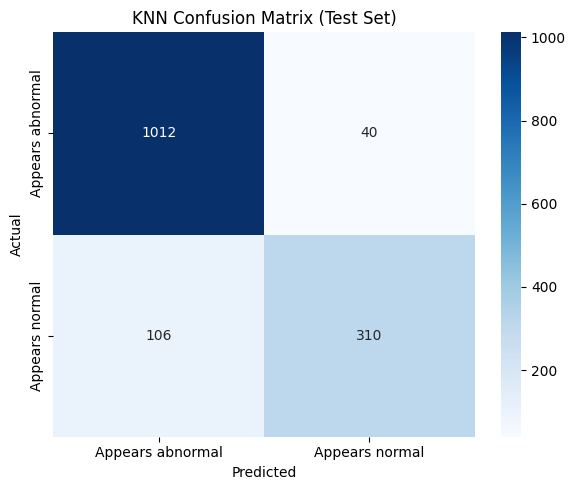


================ KNN SUMMARY ================
KNN Validation Accuracy: 0.6896
KNN Test Accuracy: 0.9005
KNN Test Precision: 0.8997
KNN Test Recall: 0.9005
KNN Test F1-score: 0.8978


In [8]:
# ============================================================
# EFFICIENTNET-B3 + KNN
# Run this in the NEXT CELL after Random Forest
# ============================================================

from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)


# ============================================================
# KNN Classifier
# ============================================================

print(
    "\n================ KNN ================"
)

knn_model = KNeighborsClassifier(
    n_neighbors=5
)


# ============================================================
# Train KNN
# ============================================================

print(
    "\nTraining KNN..."
)

knn_model.fit(
    train_features,
    train_labels
)


# ============================================================
# Validation Prediction
# ============================================================

knn_val_preds = knn_model.predict(
    val_features
)

knn_val_accuracy = np.mean(
    knn_val_preds == val_labels
)

print(
    f"\nKNN Validation Accuracy: "
    f"{knn_val_accuracy:.4f}"
)


# ============================================================
# Test Prediction
# ============================================================

knn_test_preds = knn_model.predict(
    test_features
)

knn_test_accuracy = np.mean(
    knn_test_preds == test_labels
)

print(
    f"KNN Test Accuracy: "
    f"{knn_test_accuracy:.4f}"
)


# ============================================================
# Test Metrics
# ============================================================

class_names = train_dataset.classes


knn_precision = precision_score(
    test_labels,
    knn_test_preds,
    average='weighted',
    zero_division=0
)

knn_recall = recall_score(
    test_labels,
    knn_test_preds,
    average='weighted',
    zero_division=0
)

knn_f1 = f1_score(
    test_labels,
    knn_test_preds,
    average='weighted',
    zero_division=0
)


print(
    f"KNN Test Precision: "
    f"{knn_precision:.4f}"
)

print(
    f"KNN Test Recall: "
    f"{knn_recall:.4f}"
)

print(
    f"KNN Test F1-score: "
    f"{knn_f1:.4f}"
)


# ============================================================
# Classification Report
# ============================================================

print(
    "\nKNN Per-class report:"
)

print(
    classification_report(
        test_labels,
        knn_test_preds,
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)


# ============================================================
# Confusion Matrix
# ============================================================

knn_cm = confusion_matrix(
    test_labels,
    knn_test_preds
)

plt.figure(
    figsize=(6, 5)
)

sns.heatmap(
    knn_cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel(
    'Predicted'
)

plt.ylabel(
    'Actual'
)

plt.title(
    'KNN Confusion Matrix (Test Set)'
)

plt.tight_layout()

plt.show()


# ============================================================
# KNN Summary
# ============================================================

print(
    "\n================ KNN SUMMARY ================"
)

print(
    f"KNN Validation Accuracy: "
    f"{knn_val_accuracy:.4f}"
)

print(
    f"KNN Test Accuracy: "
    f"{knn_test_accuracy:.4f}"
)

print(
    f"KNN Test Precision: "
    f"{knn_precision:.4f}"
)

print(
    f"KNN Test Recall: "
    f"{knn_recall:.4f}"
)

print(
    f"KNN Test F1-score: "
    f"{knn_f1:.4f}"
)

# Naive Bayes


NAIVE BAYES - EfficientNet-B3
Naive Bayes Validation Accuracy: 0.7750
Naive Bayes Test Accuracy: 0.8631
Naive Bayes Test Precision (Weighted): 0.8769
Naive Bayes Test Recall (Weighted): 0.8631
Naive Bayes Test F1-score (Weighted): 0.8495

Naive Bayes Classification Report:
                  precision    recall  f1-score   support

Appears abnormal     0.8451    0.9905    0.9120      1052
  Appears normal     0.9574    0.5409    0.6912       416

        accuracy                         0.8631      1468
       macro avg     0.9013    0.7657    0.8016      1468
    weighted avg     0.8769    0.8631    0.8495      1468



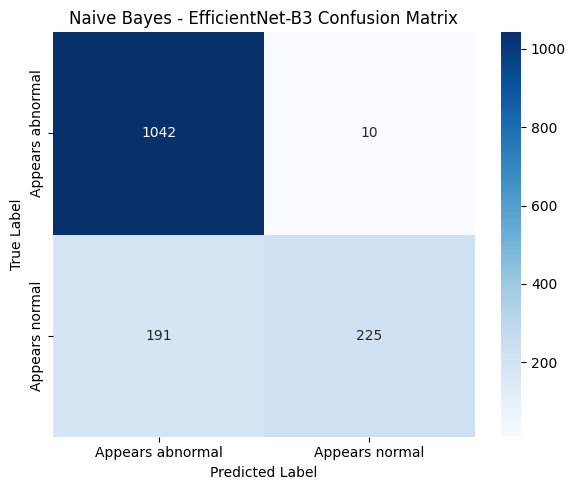


---------------- Naive Bayes ----------------
Naive Bayes Validation Accuracy: 0.7750
Naive Bayes Test Accuracy: 0.8631
Naive Bayes Test Precision: 0.8769
Naive Bayes Test Recall: 0.8631
Naive Bayes Test F1-score: 0.8495


In [9]:
# ============================================================
# NAIVE BAYES CLASSIFIER - EfficientNet-B3 Features
# ============================================================

from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
import seaborn as sns
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Train Naive Bayes
# ------------------------------------------------------------
nb_model = GaussianNB()

nb_model.fit(train_features, train_labels)

# ------------------------------------------------------------
# Validation Predictions
# ------------------------------------------------------------
val_pred_nb = nb_model.predict(val_features)

nb_val_accuracy = accuracy_score(val_labels, val_pred_nb)

# ------------------------------------------------------------
# Test Predictions
# ------------------------------------------------------------
test_pred_nb = nb_model.predict(test_features)

nb_test_accuracy = accuracy_score(test_labels, test_pred_nb)

nb_test_precision = precision_score(
    test_labels,
    test_pred_nb,
    average='weighted',
    zero_division=0
)

nb_test_recall = recall_score(
    test_labels,
    test_pred_nb,
    average='weighted',
    zero_division=0
)

nb_test_f1 = f1_score(
    test_labels,
    test_pred_nb,
    average='weighted',
    zero_division=0
)

# ------------------------------------------------------------
# Results
# ------------------------------------------------------------
print("\n" + "=" * 50)
print("NAIVE BAYES - EfficientNet-B3")
print("=" * 50)

print(f"Naive Bayes Validation Accuracy: {nb_val_accuracy:.4f}")
print(f"Naive Bayes Test Accuracy: {nb_test_accuracy:.4f}")
print(f"Naive Bayes Test Precision (Weighted): {nb_test_precision:.4f}")
print(f"Naive Bayes Test Recall (Weighted): {nb_test_recall:.4f}")
print(f"Naive Bayes Test F1-score (Weighted): {nb_test_f1:.4f}")

# ------------------------------------------------------------
# Classification Report
# ------------------------------------------------------------
print("\nNaive Bayes Classification Report:")
print(
    classification_report(
        test_labels,
        test_pred_nb,
        target_names=train_dataset.classes,
        digits=4,
        zero_division=0
    )
)

# ------------------------------------------------------------
# Confusion Matrix
# ------------------------------------------------------------
cm_nb = confusion_matrix(test_labels, test_pred_nb)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_nb,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=train_dataset.classes,
    yticklabels=train_dataset.classes
)

plt.title("Naive Bayes - EfficientNet-B3 Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# Final Summary
# ------------------------------------------------------------
print("\n---------------- Naive Bayes ----------------")
print(f"Naive Bayes Validation Accuracy: {nb_val_accuracy:.4f}")
print(f"Naive Bayes Test Accuracy: {nb_test_accuracy:.4f}")
print(f"Naive Bayes Test Precision: {nb_test_precision:.4f}")
print(f"Naive Bayes Test Recall: {nb_test_recall:.4f}")
print(f"Naive Bayes Test F1-score: {nb_test_f1:.4f}")

# Adaboost


ADABOOST - EfficientNet-B3
AdaBoost Validation Accuracy: 0.6854
AdaBoost Test Accuracy: 0.9298
AdaBoost Test Precision (Weighted): 0.9291
AdaBoost Test Recall (Weighted): 0.9298
AdaBoost Test F1-score (Weighted): 0.9291

AdaBoost Classification Report:
                  precision    recall  f1-score   support

Appears abnormal     0.9398    0.9639    0.9517      1052
  Appears normal     0.9023    0.8438    0.8720       416

        accuracy                         0.9298      1468
       macro avg     0.9210    0.9038    0.9119      1468
    weighted avg     0.9291    0.9298    0.9291      1468



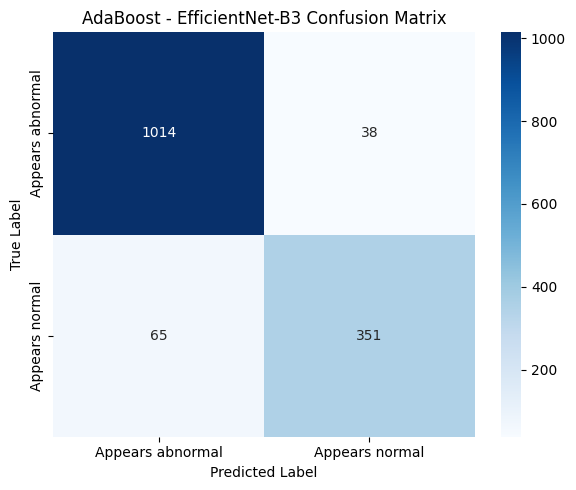


---------------- AdaBoost ----------------
AdaBoost Validation Accuracy: 0.6854
AdaBoost Test Accuracy: 0.9298
AdaBoost Test Precision: 0.9291
AdaBoost Test Recall: 0.9298
AdaBoost Test F1-score: 0.9291


In [10]:
# ============================================================
# ADABOOST CLASSIFIER - EfficientNet-B3 Features
# ============================================================

from sklearn.ensemble import AdaBoostClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
import seaborn as sns
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Train AdaBoost
# ------------------------------------------------------------
adaboost_model = AdaBoostClassifier(
    n_estimators=100,
    learning_rate=1.0,
    random_state=42
)

adaboost_model.fit(train_features, train_labels)

# ------------------------------------------------------------
# Validation Predictions
# ------------------------------------------------------------
val_pred_ada = adaboost_model.predict(val_features)

ada_val_accuracy = accuracy_score(
    val_labels,
    val_pred_ada
)

# ------------------------------------------------------------
# Test Predictions
# ------------------------------------------------------------
test_pred_ada = adaboost_model.predict(test_features)

ada_test_accuracy = accuracy_score(
    test_labels,
    test_pred_ada
)

ada_test_precision = precision_score(
    test_labels,
    test_pred_ada,
    average='weighted',
    zero_division=0
)

ada_test_recall = recall_score(
    test_labels,
    test_pred_ada,
    average='weighted',
    zero_division=0
)

ada_test_f1 = f1_score(
    test_labels,
    test_pred_ada,
    average='weighted',
    zero_division=0
)

# ------------------------------------------------------------
# Results
# ------------------------------------------------------------
print("\n" + "=" * 50)
print("ADABOOST - EfficientNet-B3")
print("=" * 50)

print(f"AdaBoost Validation Accuracy: {ada_val_accuracy:.4f}")
print(f"AdaBoost Test Accuracy: {ada_test_accuracy:.4f}")
print(f"AdaBoost Test Precision (Weighted): {ada_test_precision:.4f}")
print(f"AdaBoost Test Recall (Weighted): {ada_test_recall:.4f}")
print(f"AdaBoost Test F1-score (Weighted): {ada_test_f1:.4f}")

# ------------------------------------------------------------
# Classification Report
# ------------------------------------------------------------
print("\nAdaBoost Classification Report:")
print(
    classification_report(
        test_labels,
        test_pred_ada,
        target_names=train_dataset.classes,
        digits=4,
        zero_division=0
    )
)

# ------------------------------------------------------------
# Confusion Matrix
# ------------------------------------------------------------
cm_ada = confusion_matrix(
    test_labels,
    test_pred_ada
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_ada,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=train_dataset.classes,
    yticklabels=train_dataset.classes
)

plt.title("AdaBoost - EfficientNet-B3 Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# Final Summary
# ------------------------------------------------------------
print("\n---------------- AdaBoost ----------------")
print(f"AdaBoost Validation Accuracy: {ada_val_accuracy:.4f}")
print(f"AdaBoost Test Accuracy: {ada_test_accuracy:.4f}")
print(f"AdaBoost Test Precision: {ada_test_precision:.4f}")
print(f"AdaBoost Test Recall: {ada_test_recall:.4f}")
print(f"AdaBoost Test F1-score: {ada_test_f1:.4f}")

# XGboost


XGBOOST - EfficientNet-B3
XGBoost Validation Accuracy: 0.6917
XGBoost Test Accuracy: 0.9217
XGBoost Test Precision (Weighted): 0.9219
XGBoost Test Recall (Weighted): 0.9217
XGBoost Test F1-score (Weighted): 0.9196

XGBoost Classification Report:
                  precision    recall  f1-score   support

Appears abnormal     0.9202    0.9753    0.9469      1052
  Appears normal     0.9263    0.7861    0.8505       416

        accuracy                         0.9217      1468
       macro avg     0.9233    0.8807    0.8987      1468
    weighted avg     0.9219    0.9217    0.9196      1468



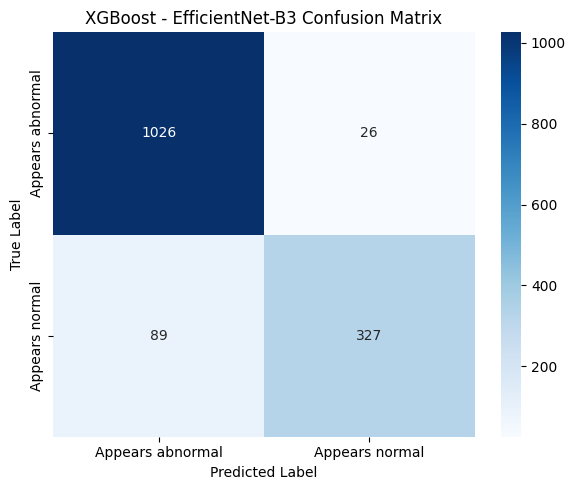


---------------- XGBoost ----------------
XGBoost Validation Accuracy: 0.6917
XGBoost Test Accuracy: 0.9217
XGBoost Test Precision: 0.9219
XGBoost Test Recall: 0.9217
XGBoost Test F1-score: 0.9196


In [11]:
# ============================================================
# XGBOOST CLASSIFIER - EfficientNet-B3 Features
# ============================================================

from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
import seaborn as sns
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Train XGBoost
# ------------------------------------------------------------
xgb_model = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=6,
    random_state=42,
    eval_metric='logloss'
)

xgb_model.fit(train_features, train_labels)

# ------------------------------------------------------------
# Validation
# ------------------------------------------------------------
val_pred_xgb = xgb_model.predict(val_features)

xgb_val_accuracy = accuracy_score(
    val_labels,
    val_pred_xgb
)

# ------------------------------------------------------------
# Test
# ------------------------------------------------------------
test_pred_xgb = xgb_model.predict(test_features)

xgb_test_accuracy = accuracy_score(
    test_labels,
    test_pred_xgb
)

xgb_test_precision = precision_score(
    test_labels,
    test_pred_xgb,
    average='weighted',
    zero_division=0
)

xgb_test_recall = recall_score(
    test_labels,
    test_pred_xgb,
    average='weighted',
    zero_division=0
)

xgb_test_f1 = f1_score(
    test_labels,
    test_pred_xgb,
    average='weighted',
    zero_division=0
)

# ------------------------------------------------------------
# Results
# ------------------------------------------------------------
print("\n" + "=" * 50)
print("XGBOOST - EfficientNet-B3")
print("=" * 50)

print(f"XGBoost Validation Accuracy: {xgb_val_accuracy:.4f}")
print(f"XGBoost Test Accuracy: {xgb_test_accuracy:.4f}")
print(f"XGBoost Test Precision (Weighted): {xgb_test_precision:.4f}")
print(f"XGBoost Test Recall (Weighted): {xgb_test_recall:.4f}")
print(f"XGBoost Test F1-score (Weighted): {xgb_test_f1:.4f}")

# ------------------------------------------------------------
# Classification Report
# ------------------------------------------------------------
print("\nXGBoost Classification Report:")
print(
    classification_report(
        test_labels,
        test_pred_xgb,
        target_names=train_dataset.classes,
        digits=4,
        zero_division=0
    )
)

# ------------------------------------------------------------
# Confusion Matrix
# ------------------------------------------------------------
cm_xgb = confusion_matrix(
    test_labels,
    test_pred_xgb
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_xgb,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=train_dataset.classes,
    yticklabels=train_dataset.classes
)

plt.title("XGBoost - EfficientNet-B3 Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# Final Summary
# ------------------------------------------------------------
print("\n---------------- XGBoost ----------------")
print(f"XGBoost Validation Accuracy: {xgb_val_accuracy:.4f}")
print(f"XGBoost Test Accuracy: {xgb_test_accuracy:.4f}")
print(f"XGBoost Test Precision: {xgb_test_precision:.4f}")
print(f"XGBoost Test Recall: {xgb_test_recall:.4f}")
print(f"XGBoost Test F1-score: {xgb_test_f1:.4f}")

# SVM


SVM - EfficientNet-B3
SVM Validation Accuracy: 0.6167
SVM Test Accuracy: 0.9237
SVM Test Precision (Weighted): 0.9253
SVM Test Recall (Weighted): 0.9237
SVM Test F1-score (Weighted): 0.9243

SVM Classification Report:
                  precision    recall  f1-score   support

Appears abnormal     0.9563    0.9363    0.9462      1052
  Appears normal     0.8470    0.8918    0.8689       416

        accuracy                         0.9237      1468
       macro avg     0.9017    0.9141    0.9075      1468
    weighted avg     0.9253    0.9237    0.9243      1468



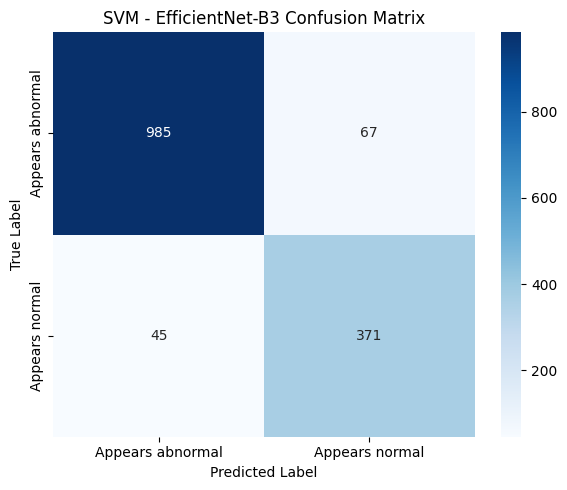


---------------- SVM ----------------
SVM Validation Accuracy: 0.6167
SVM Test Accuracy: 0.9237
SVM Test Precision: 0.9253
SVM Test Recall: 0.9237
SVM Test F1-score: 0.9243


In [13]:
# ============================================================
# SVM CLASSIFIER - EfficientNet-B3 Features
# ============================================================

from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
import seaborn as sns
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Train SVM
# ------------------------------------------------------------
svm_model = SVC(
    kernel='rbf',
    C=1.0,
    random_state=42
)

svm_model.fit(train_features, train_labels)

# ------------------------------------------------------------
# Validation
# ------------------------------------------------------------
val_pred_svm = svm_model.predict(val_features)

svm_val_accuracy = accuracy_score(
    val_labels,
    val_pred_svm
)

# ------------------------------------------------------------
# Test
# ------------------------------------------------------------
test_pred_svm = svm_model.predict(test_features)

svm_test_accuracy = accuracy_score(
    test_labels,
    test_pred_svm
)

svm_test_precision = precision_score(
    test_labels,
    test_pred_svm,
    average='weighted',
    zero_division=0
)

svm_test_recall = recall_score(
    test_labels,
    test_pred_svm,
    average='weighted',
    zero_division=0
)

svm_test_f1 = f1_score(
    test_labels,
    test_pred_svm,
    average='weighted',
    zero_division=0
)

# ------------------------------------------------------------
# Results
# ------------------------------------------------------------
print("\n" + "=" * 50)
print("SVM - EfficientNet-B3")
print("=" * 50)

print(f"SVM Validation Accuracy: {svm_val_accuracy:.4f}")
print(f"SVM Test Accuracy: {svm_test_accuracy:.4f}")
print(f"SVM Test Precision (Weighted): {svm_test_precision:.4f}")
print(f"SVM Test Recall (Weighted): {svm_test_recall:.4f}")
print(f"SVM Test F1-score (Weighted): {svm_test_f1:.4f}")

# ------------------------------------------------------------
# Classification Report
# ------------------------------------------------------------
print("\nSVM Classification Report:")
print(
    classification_report(
        test_labels,
        test_pred_svm,
        target_names=train_dataset.classes,
        digits=4,
        zero_division=0
    )
)

# ------------------------------------------------------------
# Confusion Matrix
# ------------------------------------------------------------
cm_svm = confusion_matrix(
    test_labels,
    test_pred_svm
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_svm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=train_dataset.classes,
    yticklabels=train_dataset.classes
)

plt.title("SVM - EfficientNet-B3 Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# Final Summary
# ------------------------------------------------------------
print("\n---------------- SVM ----------------")
print(f"SVM Validation Accuracy: {svm_val_accuracy:.4f}")
print(f"SVM Test Accuracy: {svm_test_accuracy:.4f}")
print(f"SVM Test Precision: {svm_test_precision:.4f}")
print(f"SVM Test Recall: {svm_test_recall:.4f}")
print(f"SVM Test F1-score: {svm_test_f1:.4f}")